# mc-engine: an end-to-end walkthrough

This notebook re-runs the key results of the project at reduced size, so that it executes in
about a minute. The full-size numbers and plots in the README come from the scripts in
`benchmarks/`. Every claim made here is computed in the cell beneath it.

1. Pricing and *validating* the uncertainty estimate
2. Heston: Euler vs QE discretisation bias
3. Variance reduction and convergence rates
4. Greeks, and where the pathwise method breaks
5. American options: Longstaff-Schwartz vs a binomial tree
6. Risk: VaR/ES and a backtest on real data
7. Performance: numpy vs numba

In [1]:
import dataclasses
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binom

from mc_engine import GBM, Heston, Merton, mc_price
from mc_engine.analytic import bs_digital_delta, bs_price, heston_price, merton_price
from mc_engine.payoffs import ArithmeticAsian, Digital, European, UpAndOutCall

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")
plt.rcParams["figure.figsize"] = (8, 3.5)

## 1. Pricing, and checking that the confidence interval means what it says

A Monte Carlo price is only useful with an honest error bar. Below, the 95% CI is checked
against Black-Scholes over 300 independent seeds. If the estimator and its standard error are
right, the number of CIs containing the true price is Binomial(300, 0.95).

In [2]:
gbm = GBM(S0=100, r=0.05, sigma=0.2)
exact = float(bs_price(100, 100, 1.0, 0.05, 0.2))
print(mc_price(gbm, European(100), 1.0, 1, 200_000, rng=0), f"\nBlack-Scholes: {exact:.6f}")

hits = sum(
    lo <= exact <= hi
    for lo, hi in (mc_price(gbm, European(100), 1.0, 1, 10_000, rng=s).ci95 for s in range(300))
)
lo, hi = binom.ppf([0.0005, 0.9995], 300, 0.95)
print(f"coverage: {hits}/300 = {hits / 300:.1%}  (99.9% acceptance band: {lo:.0f}-{hi:.0f})")

price=10.464451  se=0.032937  95% CI=[10.399897, 10.529006]  N=200,000  (0.004s) 
Black-Scholes: 10.450584
coverage: 278/300 = 92.7%  (99.9% acceptance band: 271-296)


The same check against semi-analytic benchmarks: the Merton jump-diffusion series, and
the Heston characteristic function (two independent Fourier inversions that agree with each other).

In [3]:
merton = Merton(S0=100, r=0.05, sigma=0.2, lam=0.5, mu_j=-0.1, sigma_j=0.15)
heston = Heston(S0=100, v0=0.04, kappa=1.5, theta=0.04, xi=0.6, rho=-0.7, r=0.03)
rows = []
for name, model, steps, ref in [
    ("Merton", merton, 4, merton_price(merton, 100, 1.0)),
    ("Heston QE", heston, 50, heston_price(heston, 100, 1.0)),
]:
    r = mc_price(model, European(100), 1.0, steps, 200_000, rng=1)
    rows.append(
        dict(
            model=name,
            mc=r.price,
            se=r.std_error,
            reference=ref,
            error_in_se=(r.price - ref) / r.std_error,
        )
    )
print(
    "Heston CF, Lewis vs Gil-Pelaez:",
    heston_price(heston, 100, 1.0),
    heston_price(heston, 100, 1.0, method="gil_pelaez"),
)
pd.DataFrame(rows)

Heston CF, Lewis vs Gil-Pelaez: 8.581899641449873 8.581899641449837


,model,mc,se,reference,error_in_se
0,Merton,11.69643,0.03699,11.66167,0.93974
1,Heston QE,8.60984,0.02138,8.58190,1.30711


## 2. Heston: discretisation bias of Euler vs QE

Andersen's test case I (vol-of-vol 1, correlation -0.9, 10 years) badly violates the Feller
condition, so the variance spends much of its time near zero. Full-truncation Euler's bias
shrinks only linearly in dt, while QE's is already statistically invisible at dt = 1/4.
Unlike MC noise, this bias does **not** fall as you add paths.

In [4]:
case1 = Heston(S0=100, v0=0.04, kappa=0.5, theta=0.04, xi=1.0, rho=-0.9, r=0.0)
ref = heston_price(case1, 100, 10.0)
rows = []
for spy in (1, 4, 16):
    for scheme in ("euler", "qe"):
        r = mc_price(
            dataclasses.replace(case1, scheme=scheme),
            European(100),
            10.0,
            10 * spy,
            50_000,
            rng=spy,
        )
        rows.append(
            dict(
                dt=f"1/{spy}",
                scheme=scheme,
                bias=r.price - ref,
                bias_in_se=(r.price - ref) / r.std_error,
            )
        )
print(f"exact (characteristic function): {ref:.4f}")
(
    pd.DataFrame(rows)
    .pivot(index="dt", columns="scheme", values=["bias", "bias_in_se"])
    .reindex(["1/1", "1/4", "1/16"])
)

exact (characteristic function): 13.0847


bias          bias_in_se         
scheme   euler       qe      euler       qe
dt                                         
1/1    6.27372  0.15721   47.81801  2.80184
1/4    2.13866  0.06579   28.26759  1.10078
1/16   0.54110 -0.01750    8.55032 -0.29474

## 3. Variance reduction and convergence

Arithmetic Asian (12 monthly fixings). The geometric Asian has a closed form and is
almost perfectly correlated with the arithmetic one, which makes it a superb control variate.
RQMC with a Brownian bridge does almost as well with no problem-specific knowledge at all.
*Efficiency gain* accounts for runtime: it is the factor by which time-to-accuracy falls.

In [5]:
from mc_engine.variance_reduction import (
    control_variate_price,
    convergence_study,
    efficiency_table,
    geometric_asian_control,
    loglog_slope,
    rqmc_price,
)

asian, N = ArithmeticAsian(100), 2**17
ctrl, mu = geometric_asian_control(gbm, 100, 1.0, 12)
res = {
    "plain": mc_price(gbm, asian, 1.0, 12, N, rng=2),
    "antithetic": mc_price(gbm, asian, 1.0, 12, N, rng=2, antithetic=True),
    "control variate": control_variate_price(gbm, asian, ctrl, mu, 1.0, 12, N, rng=2),
    "RQMC + bridge": rqmc_price(gbm, asian, 1.0, 12, N // 16, 16, seed=2),
}
print("pilot correlation arithmetic vs geometric:", res["control variate"].pilot_correlation)
efficiency_table(res)[["price", "std_error", "vr_ratio", "efficiency_gain"]]

pilot correlation arithmetic vs geometric: 0.9995734960706889


,price,std_error,vr_ratio,efficiency_gain
plain,6.16189,0.02358,1.00000,1.00000
antithetic,6.16502,0.01634,2.08302,2.45968
control variate,6.15636,0.00066,"1,274.93767",943.65298
RQMC + bridge,6.15656,0.00049,"2,305.04522","1,280.04837"


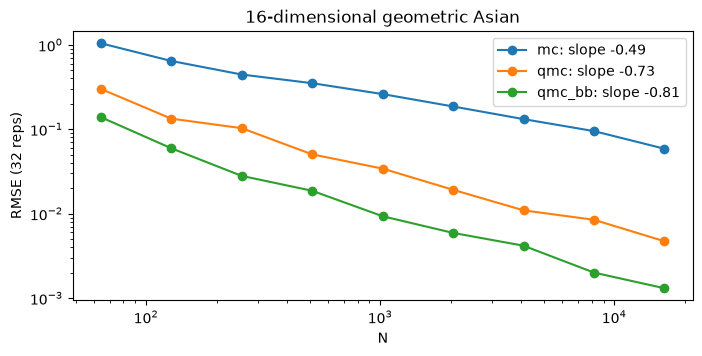

In [6]:
from mc_engine.analytic import geometric_asian_price
from mc_engine.payoffs import GeometricAsian
from mc_engine.pricer import time_grid

exact_g = geometric_asian_price(100, 100, 0.05, 0.2, time_grid(1.0, 16)[1:])
ns = [2**k for k in range(6, 15)]
fig, ax = plt.subplots()
for method in ("mc", "qmc", "qmc_bb"):
    df = convergence_study(gbm, GeometricAsian(100), 1.0, 16, exact_g, ns, 32, method, seed=3)
    s = loglog_slope(df.n_paths.to_numpy(), df.rmse.to_numpy())
    ax.loglog(df.n_paths, df.rmse, "o-", label=f"{method}: slope {s:.2f}")
ax.set(xlabel="N", ylabel="RMSE (32 reps)", title="16-dimensional geometric Asian")
ax.legend()
plt.show()

## 4. Greeks: three estimators, and where pathwise breaks

For a call, all three estimators agree with Black-Scholes. Pathwise and FD with common random
numbers have the lowest variance, and likelihood ratio is noisier. For a **digital**, the payoff is
a step function, so its derivative is zero almost everywhere and the pathwise delta is identically
0. For a **knock-out barrier**, pathwise misses the paths a bump pushes over the barrier.
Likelihood ratio differentiates the density instead, so it handles both.

In [7]:
from mc_engine.analytic import bs_delta, bs_gamma, bs_rho, bs_vega
from mc_engine.greeks import fd_greeks, likelihood_ratio_greeks, pathwise_greeks

g2 = GBM(S0=100, r=0.05, sigma=0.2, q=0.01)
a = (100, 105, 1.0, 0.05, 0.2, 0.01)
exact = {"delta": bs_delta(*a), "gamma": bs_gamma(*a), "vega": bs_vega(*a), "rho": bs_rho(*a)}
table = {"exact": {k: float(v) for k, v in exact.items()}}
methods = [("FD+CRN", fd_greeks), ("pathwise", pathwise_greeks), ("LR", likelihood_ratio_greeks)]
for name, fn in methods:
    est = fn(g2, European(105), 1.0, 1, 100_000, seed=4)
    table[name] = {k: f"{est[k].value:.4f} ± {est[k].std_error:.1e}" for k in exact}
pd.DataFrame(table)

,exact,FD+CRN,pathwise,LR
delta,0.51715,0.5200 ± 1.8e-03,0.5200 ± 1.9e-03,0.5171 ± 4.1e-03
gamma,0.01972,0.0197 ± 3.6e-04,0.0198 ± 1.2e-04,0.0194 ± 3.8e-04
vega,39.43528,39.5649 ± 2.3e-01,39.5650 ± 2.3e-01,38.7343 ± 7.6e-01
rho,44.22343,44.4804 ± 1.6e-01,44.4822 ± 1.6e-01,44.1916 ± 3.7e-01


In [8]:
dd = float(bs_digital_delta(*a))
pw = pathwise_greeks(g2, Digital(105), 1.0, 1, 100_000, seed=5)["delta"]
lr = likelihood_ratio_greeks(g2, Digital(105), 1.0, 1, 100_000, seed=5)["delta"]
print(f"digital delta: exact {dd:.5f} | pathwise {pw} | LR {lr}")

b, m = UpAndOutCall(100, 130), GBM(S0=100, r=0.05, sigma=0.2)
pwb = pathwise_greeks(m, b, 1.0, 50, 100_000, seed=6)["delta"]
lrb = likelihood_ratio_greeks(m, b, 1.0, 50, 100_000, seed=7)["delta"]
fdb = fd_greeks(m, b, 1.0, 50, 100_000, seed=8, bump_spot=0.5)["delta"]
print(f"barrier delta: pathwise {pwb} | LR {lrb} | FD {fdb}")

digital delta: exact 0.01878 | pathwise +0.000000 (se 0.00e+00) | LR +0.018762 (se 8.82e-05)


barrier delta: pathwise +0.382235 (se 1.61e-03) | LR +0.058308 (se 8.41e-03) | FD +0.061664 (se 8.52e-03)


## 5. American put: Longstaff-Schwartz vs a binomial tree

The tree uses the *same* 50 exercise dates (Bermudan), so the comparison isolates the LSM
algorithm itself from the (real, economic) Bermudan-vs-American gap. The out-of-sample estimate
applies a frozen exercise rule to fresh paths, so it is a lower bound. The in-sample estimate
overfits the paths it prices.

In [9]:
from mc_engine.american import lsm_price
from mc_engine.analytic.binomial import crr_price

rows = []
for S0 in (36.0, 40.0, 44.0):
    berm = crr_price(S0, 40, 1.0, 0.06, 0.2, n_steps=5000, exercise="bermudan", n_exercise_dates=50)
    amer = crr_price(S0, 40, 1.0, 0.06, 0.2, n_steps=5000)
    r = lsm_price(GBM(S0, 0.06, 0.2), 40, 1.0, 50, 100_000, seed=int(S0))
    rows.append(
        dict(
            S0=S0,
            american_tree=amer,
            bermudan_tree=berm,
            lsm=r.price,
            se=r.std_error,
            in_sample=r.in_sample_price,
            lsm_minus_tree_se=(r.price - berm) / r.std_error,
        )
    )
pd.DataFrame(rows)

,S0,american_tree,bermudan_tree,lsm,se,in_sample,lsm_minus_tree_se
0,36.00000,4.48669,4.47791,4.46357,0.00915,4.47931,-1.56746
1,40.00000,2.31960,2.31404,2.31716,0.00863,2.29919,0.36108
2,44.00000,1.11301,1.10988,1.10889,0.00641,1.09274,-0.15443


## 6. Risk: VaR/ES and a backtest on 13 years of real data

Five stocks (cached in `data/`, so no network access is needed). First, a VaR/ES table with
Gaussian vs Student-t shocks. Then a rolling, no-look-ahead 99% VaR backtest. A static
volatility window fails both Kupiec (too many exceedances) and Christoffersen (clustering). EWMA
volatility fixes the clustering. Fat tails reduce, but do not eliminate, the excess at 99%.

In [10]:
from mc_engine.risk import Portfolio, backtest_summary, risk_report, rolling_var_backtest
from mc_engine.risk.data import load_prices, log_returns

rets = log_returns(load_prices(cache_dir=ROOT / "data"))
spot = load_prices(cache_dir=ROOT / "data").iloc[-1].to_numpy()
port = Portfolio(spot=spot, vol=rets.std().to_numpy() * np.sqrt(252), shares=200_000 / spot)
corr = rets.corr().to_numpy()
pd.concat(
    {
        d: risk_report(
            port, np.zeros(5), corr, dist=d, nu=5.0 if d == "t" else None, n_sims=200_000, seed=9
        ).set_index(["horizon_days", "alpha"])
        for d in ("normal", "t")
    },
    axis=1,
).round(0)

normal                                       t  \
                              VaR           ES sqrt_time_var          VaR   
horizon_days alpha                                                          
1            0.95000 18,651.00000 23,271.00000  18,651.00000 17,677.00000   
             0.99000 26,177.00000 29,965.00000  26,177.00000 29,387.00000   
10           0.95000 57,985.00000 72,015.00000  58,978.00000 57,597.00000   
             0.99000 80,736.00000 92,092.00000  82,780.00000 83,009.00000   

                                                 
                               ES sqrt_time_var  
horizon_days alpha                               
1            0.95000 25,110.00000  17,677.00000  
             0.99000 38,039.00000  29,387.00000  
10           0.95000 73,528.00000  55,901.00000  
             0.99000 97,678.00000  92,931.00000

In [11]:
w = np.ones(5) / 5
summ = []
for method, vol in [("normal", "window"), ("normal", "ewma"), ("t", "ewma")]:
    bt = rolling_var_backtest(rets, w, method, vol, window=500, n_sims=5_000, seed=1)
    s = backtest_summary(bt)
    s.insert(0, "model", f"{method}/{vol}")
    summ.append(s)
pd.concat(summ)[["model", "alpha", "exceedances", "expected", "kupiec_p", "christoffersen_p"]]

,model,alpha,exceedances,expected,kupiec_p,christoffersen_p
0,normal/window,0.95000,140,163.65000,0.05203,0.00002
1,normal/window,0.99000,71,32.73000,0.00000,0.00000
0,normal/ewma,0.95000,169,163.65000,0.66946,0.65677
1,normal/ewma,0.99000,66,32.73000,0.00000,0.58102
0,t/ewma,0.95000,183,163.65000,0.12744,0.37741
1,t/ewma,0.99000,54,32.73000,0.00063,0.30259


## 7. Performance

The numba kernel receives exactly the same random numbers as the numpy code, so the paths agree to
round-off, and it runs the whole time step in a parallel compiled loop.

In [12]:
fast = dataclasses.replace(heston, backend="numba")
t = np.linspace(0, 1, 101)
fast.simulate(1000, t, 0)  # JIT / cache warm-up
a_, b_ = heston.simulate(50_000, t, 1).paths, fast.simulate(50_000, t, 1).paths
print("max relative difference numpy vs numba:", np.max(np.abs(a_ / b_ - 1)))
for name, m in (("numpy", heston), ("numba", fast)):
    t0 = time.perf_counter()
    mc_price(m, European(100), 1.0, 100, 2**17, rng=2)
    dt_ = time.perf_counter() - t0
    print(f"{name}: {2**17 / dt_:,.0f} paths/s")

max relative difference numpy vs numba: 1.7763568394002505e-14


numpy: 100,301 paths/s


numba: 591,114 paths/s


## Takeaways

* A Monte Carlo number is a *statistical estimate*: test its error bar (coverage), not only its value.
* Discretisation bias and Monte Carlo noise are different errors. Only the second shrinks with N.
* The best variance reduction uses structure: a control with a known mean beat everything except RQMC with a bridge.
* The pathwise method needs Lipschitz payoffs. Likelihood ratio needs only a smooth density.
* LSM out-of-sample estimates are lower bounds and in-sample estimates are biased upward, so the truth is bracketed.
* Real equity returns are skewed and clustered: volatility dynamics matter more than tail shape, and a symmetric t still under-predicts 99% losses.